In [1]:
print("Smart Waste Classification Project")
print("Project setup successful!")

Smart Waste Classification Project
Project setup successful!


In [2]:
import os
import zipfile
import urllib.request

url = "https://huggingface.co/datasets/garythung/trashnet/resolve/main/dataset-resized.zip"
zip_path = "/content/waste_dataset.zip"

print("Downloading waste dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download complete!")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/waste_data")

print("Dataset extracted successfully!")
print("Files downloaded:", os.path.getsize(zip_path) // (1024 * 1024), "MB")

Download complete!
Dataset extracted successfully!
Files downloaded: 40 MB


In [3]:
import os

dataset_path = "/content/waste_data"

for folder in sorted(os.listdir(dataset_path)):
    path = os.path.join(dataset_path, folder)

    if os.path.isdir(path):
        images = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(folder, ":", len(images), "images")

__MACOSX : 0 images
dataset-resized : 0 images


In [4]:
import os

root_path = "/content/waste_data"

for root, dirs, files in os.walk(root_path):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        print(root, "->", len(images), "images")

/content/waste_data/dataset-resized/paper -> 594 images
/content/waste_data/dataset-resized/plastic -> 482 images
/content/waste_data/dataset-resized/metal -> 410 images
/content/waste_data/dataset-resized/cardboard -> 403 images
/content/waste_data/dataset-resized/glass -> 501 images
/content/waste_data/dataset-resized/trash -> 137 images
/content/waste_data/__MACOSX/dataset-resized/cardboard -> 1 images


In [5]:
import tensorflow as tf

DATASET_PATH = "/content/waste_data/dataset-resized"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Categories:", class_names)
print("Dataset preparation completed!")

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Dataset preparation completed!


In [6]:
import tensorflow as tf

# Load a pretrained CNN
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Build our waste classification model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    6,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

# Configure training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 113s 2s/step - accuracy: 0.5865 - loss: 1.0765 - val_accuracy: 0.7584 - val_loss: 0.7000
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.7888 - loss: 0.5991 - val_accuracy: 0.8000 - val_loss: 0.5752
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.8259 - loss: 0.4849 - val_accuracy: 0.8119 - val_loss: 0.5432
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.8477 - loss: 0.4146 - val_accuracy: 0.8139 - val_loss: 0.5165
Epoch 5/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.8754 - loss: 0.3621 - val_accuracy: 0.8317 - val_loss: 0.4901


In [8]:
# Save the trained deep-learning model
model.save("/content/smart_waste_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [9]:
val_loss, val_accuracy = model.evaluate(val_ds)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8317 - loss: 0.4901
Validation Loss: 0.4901
Validation Accuracy: 83.17%


Predicted category: plastic
Confidence: 60.29%


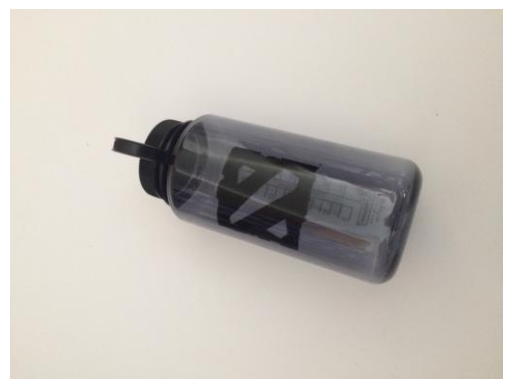

In [12]:
import os
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select an existing image from the dataset
image_path = "/content/waste_data/dataset-resized/plastic/plastic1.jpg"

# Find a plastic image if that filename does not exist
if not os.path.exists(image_path):
    folder = "/content/waste_data/dataset-resized/plastic"
    image_path = os.path.join(
        folder,
        next(f for f in os.listdir(folder)
             if f.lower().endswith((".jpg", ".jpeg", ".png")))
    )

# Load the image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare and predict
img_array = np.array(img_resized, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

predictions = model.predict(img_array, verbose=0)[0]
predicted_index = np.argmax(predictions)

print("Predicted category:", class_names[predicted_index])
print(f"Confidence: {predictions[predicted_index] * 100:.2f}%")

plt.imshow(img)
plt.axis("off")
plt.show()

In [13]:
!pip -q install gradio

import gradio as gr
import numpy as np
from PIL import Image

def classify_waste(image):
    image = image.convert("RGB").resize((224, 224))
    arr = np.array(image, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)

    predictions = model.predict(arr, verbose=0)[0]

    return {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

demo = gr.Interface(
    fn=classify_waste,
    inputs=gr.Image(type="pil", label="Upload waste image"),
    outputs=gr.Label(num_top_classes=6),
    title="Smart Waste Classification Using Deep Learning",
    description="Upload an image to predict its waste category."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a9e5f44b90513e3076.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:
from google.colab import files

files.download("/content/smart_waste_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>